In [ ]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')

# import os
# from getpass import getpass
# from huggingface_hub import login

# try:
#     # Optional: load from a .env file (pip install python-dotenv)
#     from dotenv import load_dotenv
#     load_dotenv()
# except ImportError:
#     pass

# try:
#     token = os.environ.get("HF_TOKEN") or getpass("Enter your Hugging Face token: ")
#     login(token=token)
#     print("Hugging Face login: OK")
# except Exception as exc:
#     print("HF login was not completed automatically:", exc)
#     print("If the model is already cached and accessible, you can continue.")

In [8]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

Loading weights: 100%|██████████| 146/146 [00:01<00:00, 127.51it/s]


In [9]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""


'\n\nHint:\n# Analyze the weights of the query projection layer (q_proj) where layer = k\n q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()\n\n# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).\n U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)\n\n# Compute the retained energy ratio (Cumulative energy) of each singular value.\nenergy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100\n'

Loading weights: 100%|██████████| 146/146 [00:02<00:00, 55.23it/s]


Layer 0: shape=(2048, 2048), min rank for >=50% energy = 62 (50.17%)
Layer 7: shape=(2048, 2048), min rank for >=50% energy = 120 (50.20%)
Layer 15: shape=(2048, 2048), min rank for >=50% energy = 84 (50.12%)
Saved: kaggle\working\q4_svd_analysis\q4_svd_analysis.png


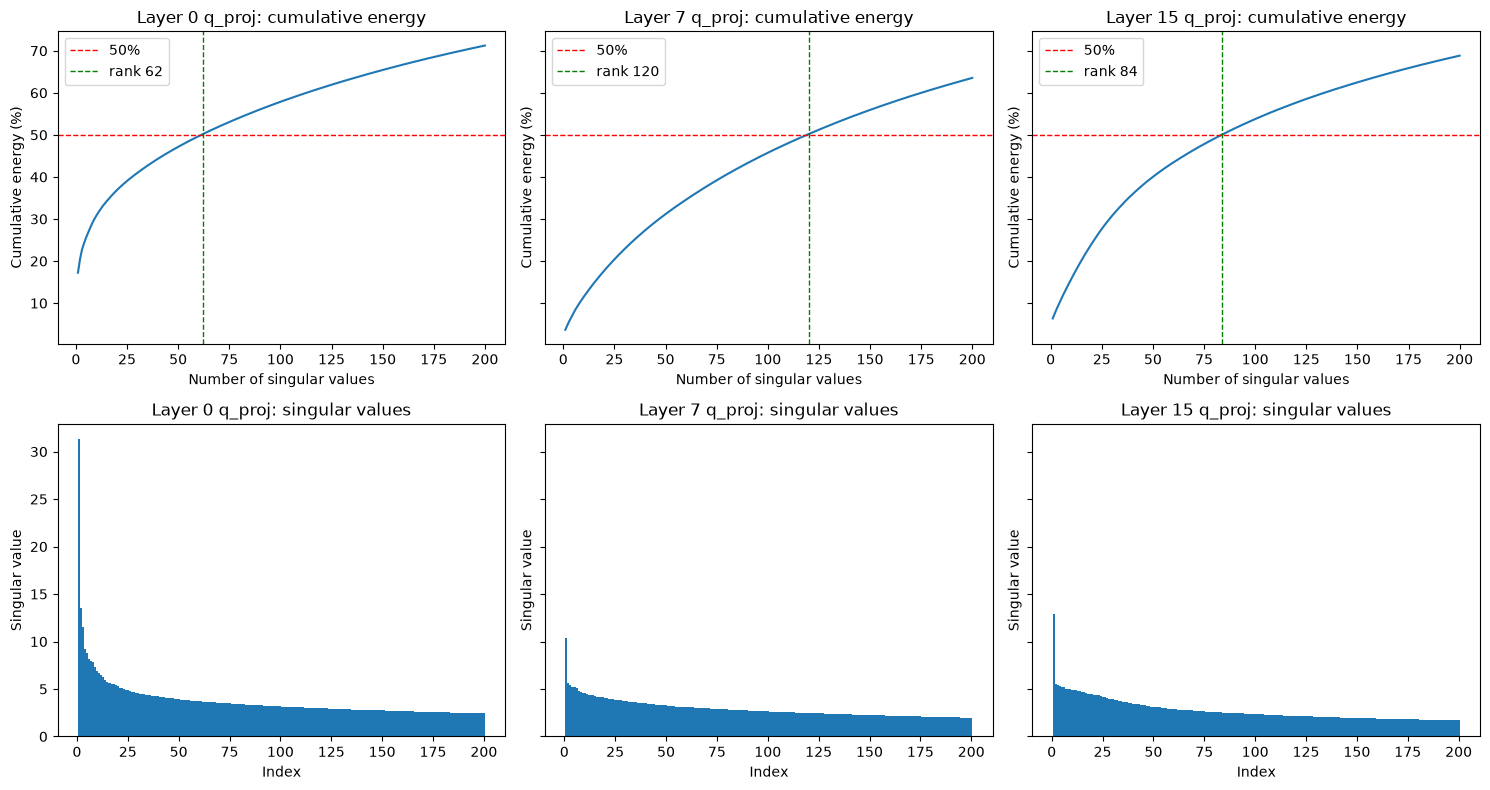

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM

MODEL_ID = 'meta-llama/Llama-3.2-1B'
LAYERS = [0, 7, 15]
THRESHOLD = 50.0     # percent cumulative energy
TOP_N = 200          # singular values to visualize

OUT = Path('./kaggle/working/q4_svd_analysis')
OUT.mkdir(parents=True, exist_ok=True)

# Original model only, no fine-tuning, CPU is enough
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16)
model.eval()

results = {}
spectra = {}

for k in LAYERS:
    # Analyze the weights of q_proj at layer k
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

    # SVD (no target rank: keep all singular values)
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    # Cumulative energy (%) over ALL singular values
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # Minimum target rank with >= 50% cumulative energy
    min_rank = int((energy_ratios >= THRESHOLD).nonzero()[0].item()) + 1

    spectra[k] = (S[:TOP_N].cpu().numpy(), energy_ratios[:TOP_N].cpu().numpy())
    results[k] = {
        'shape': list(q_weight.shape),
        'num_singular_values': int(S.numel()),
        'min_rank_for_50pct_energy': min_rank,
        'cum_energy_at_that_rank_pct': float(energy_ratios[min_rank - 1]),
    }
    print(f'Layer {k}: shape={tuple(q_weight.shape)}, '
          f'min rank for >=50% energy = {min_rank} '
          f'({energy_ratios[min_rank - 1]:.2f}%)')

(OUT / 'q4_min_rank.json').write_text(json.dumps(results, indent=2))

# Visualization: row 1 = cumulative energy (line), row 2 = singular values (bar)
fig, axes = plt.subplots(2, len(LAYERS), figsize=(15, 8), sharey='row')
x = list(range(1, TOP_N + 1))

for j, k in enumerate(LAYERS):
    S_np, cum_np = spectra[k]
    min_rank = results[k]['min_rank_for_50pct_energy']

    ax = axes[0, j]
    ax.plot(x, cum_np)
    ax.axhline(THRESHOLD, color='r', linestyle='--', linewidth=1, label='50%')
    if min_rank <= TOP_N:
        ax.axvline(min_rank, color='g', linestyle='--', linewidth=1,
                   label=f'rank {min_rank}')
    ax.set_title(f'Layer {k} q_proj: cumulative energy')
    ax.set_xlabel('Number of singular values')
    ax.set_ylabel('Cumulative energy (%)')
    ax.legend()

    ax = axes[1, j]
    ax.bar(x, S_np, width=1.0)
    ax.set_title(f'Layer {k} q_proj: singular values')
    ax.set_xlabel('Index')
    ax.set_ylabel('Singular value')

plt.tight_layout()
plt.savefig(OUT / 'q4_svd_analysis.png', dpi=200)
print('Saved:', OUT / 'q4_svd_analysis.png')

# Optional: also save each layer as its own figure (handy for the report)
for k in LAYERS:
    S_np, cum_np = spectra[k]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(x, cum_np)
    ax[0].axhline(THRESHOLD, color='r', linestyle='--', linewidth=1)
    ax[0].set_title(f'Layer {k}: cumulative energy (%)')
    ax[0].set_xlabel('Number of singular values')
    ax[1].bar(x, S_np, width=1.0)
    ax[1].set_title(f'Layer {k}: singular values')
    ax[1].set_xlabel('Index')
    plt.tight_layout()
    plt.savefig(OUT / f'q4_layer{k}.png', dpi=200)
    plt.close(fig)